# LAB 06 — Attention Mechanism

**Notebook thực nghiệm:** scaling/temperature, Experiment 1–5, application và error analysis.
**Chuẩn bị:** Đặt `attention_numpy.py` cùng notebook. Upload tệp **`aclImdb_v1.tar.gz`** vào mục Files của Google Colab (đường dẫn `/content/aclImdb_v1.tar.gz`). Đến Experiment 4, notebook sẽ đọc và giải nén bằng **đúng cách của W5**, không yêu cầu upload bằng hộp thoại.

## 0. Setup
Chỉ khai báo thư viện, thông số và các hàm vẽ dùng chung.

In [1]:
import hashlib
import math
import random
import re
import time
import tarfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from attention_numpy import stable_softmax, dot_product_attention, scaled_dot_product_attention, self_attention

SEED = 42
MAX_VOCAB, MAX_LEN, BATCH_SIZE = 20000, 200, 128
EMBED_DIM, HIDDEN_SIZE, EPOCHS, LR = 64, 64, 3, 1e-3
PAD, UNK = 0, 1
OUTPUT_DIR = Path.cwd()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

def tokenizer(text):
    text = re.sub(r'<br\s*/?>', ' ', str(text).lower())
    return re.findall(r'[a-z0-9]+', text)

def clean_text(text):
    return ' '.join(tokenizer(text))

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

sns.set_theme(style='whitegrid')
print('Device:', device)

Device: cuda


## 1. Temperature & Scaling (mục 15)
Thay đổi temperature trên cùng scores; kiểm tra scaling bằng cách chia scores cho $\sqrt{d_k}$.

,Temperature,Max weight,Entropy
0,0.5,0.7091,0.8064
1,1.0,0.5037,1.1700
2,2.0,0.3763,1.3234


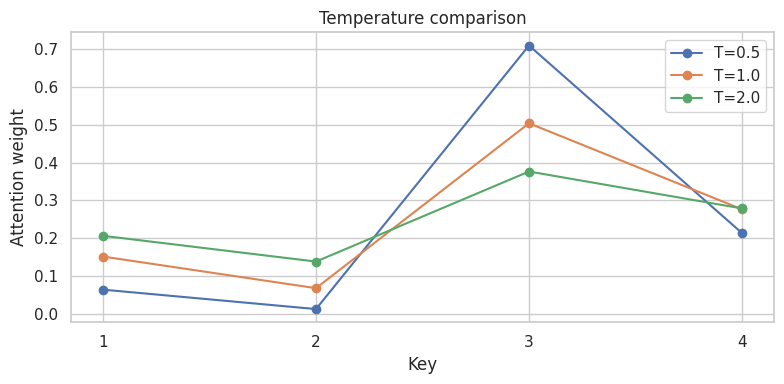

,Key,Unscaled,Scaled
0,1,0.0007,0.0698
1,2,0.7086,0.3993
2,3,0.0002,0.0490
3,4,0.0226,0.1687
4,5,0.2680,0.3132


Unscaled: max=0.7086, entropy=0.6889
Scaled:   max=0.3993, entropy=1.3640


In [2]:
scores = np.array([0.2, -0.6, 1.4, 0.8])
temperatures = [0.5, 1.0, 2.0]
weights_by_t = {t: stable_softmax(scores / t) for t in temperatures}

def entropy(weights):
    weights = np.asarray(weights)
    return float(-(weights * np.log(np.clip(weights, 1e-12, 1))).sum())

temperature_df = pd.DataFrame([
    {'Temperature': t, 'Max weight': w.max(), 'Entropy': entropy(w)}
    for t, w in weights_by_t.items()
])
display(temperature_df.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for t, weights in weights_by_t.items():
    ax.plot(np.arange(1, 5), weights, 'o-', label=f'T={t}')
ax.set(xlabel='Key', ylabel='Attention weight', title='Temperature comparison', xticks=range(1, 5))
ax.legend()
save_figure(fig, 'temperature_distributions.png')

rng = np.random.default_rng(SEED + 1)
Q, K = rng.normal(size=(1, 16)), rng.normal(size=(5, 16))
raw_scores = (Q @ K.T)[0]
scaled_scores = raw_scores / np.sqrt(K.shape[1])
raw_weights, scaled_weights = stable_softmax(raw_scores), stable_softmax(scaled_scores)
scaling_df = pd.DataFrame({'Key': range(1, 6), 'Unscaled': raw_weights, 'Scaled': scaled_weights})
display(scaling_df.round(4))
print(f'Unscaled: max={raw_weights.max():.4f}, entropy={entropy(raw_weights):.4f}')
print(f'Scaled:   max={scaled_weights.max():.4f}, entropy={entropy(scaled_weights):.4f}')

**Phân tích — Temperature và scaling ảnh hưởng thế nào?**

Từ bảng kết quả, khi temperature tăng từ $T=0.5$ lên $T=1.0$ rồi $T=2.0$, **max attention weight** lần lượt giảm **0.7091 → 0.5037 → 0.3763**, trong khi **entropy** tăng **0.8064 → 1.1700 → 1.3234**. Như vậy, temperature thấp tạo phân phối tập trung hơn; temperature cao làm phân phối trải đều hơn.

Trong thử nghiệm scaling với $d_k=16$ ($\sqrt{d_k}=4$), max weight giảm từ **0.7086** xuống **0.3993** và entropy tăng từ **0.6889** lên **1.3640**. Trên bộ scores đang xét, scaling làm softmax bớt tập trung, giúp hạn chế tình trạng phân phối quá sắc.

**Tại sao trừ max không làm thay đổi softmax?** Vì với $m=\max_j s_j$, ta có $\frac{e^{s_i-m}}{\sum_j e^{s_j-m}}=\frac{e^{s_i}}{\sum_j e^{s_j}}$; cùng một hệ số bị triệt tiêu ở tử và mẫu. Phép trừ này giảm nguy cơ tràn số khi tính $e^{s_i}$.

## 2. Experiment 1 — Attention distribution (mục 18)
Query và keys được lấy ngẫu nhiên có seed, **chưa huấn luyện**.

,Token,Score,Attention
0,the,3.83207,0.00700
1,movie,-3.64874,0.00000
2,was,2.15098,0.00130
3,surprisingly,4.67163,0.01620
4,good,1.84509,0.00096
5,despite,6.82981,0.14021
6,a,-2.48270,0.00001
7,very,7.54822,0.28760
8,slow,8.19017,0.54649
9,beginning,0.43793,0.00023


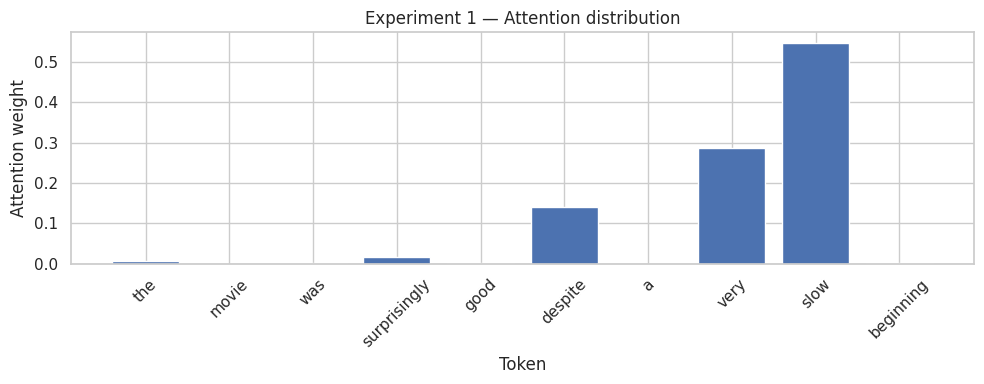

In [3]:
sentence = 'The movie was surprisingly good despite a very slow beginning.'
tokens_exp1 = tokenizer(sentence)
rng = np.random.default_rng(SEED + 2)
keys_exp1 = rng.normal(size=(len(tokens_exp1), 8))
values_exp1 = rng.normal(size=(len(tokens_exp1), 5))
query_exp1 = rng.normal(size=8)
scores_exp1, weights_exp1, _ = dot_product_attention(query_exp1, keys_exp1, values_exp1)
distribution_df = pd.DataFrame({'Token': tokens_exp1,
    'Score': scores_exp1[0], 'Attention': weights_exp1[0]})
display(distribution_df.round(5))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(tokens_exp1, weights_exp1[0])
ax.set(xlabel='Token', ylabel='Attention weight', title='Experiment 1 — Attention distribution')
ax.tick_params(axis='x', rotation=45)
save_figure(fig, 'attention_distribution.png')

**Phân tích — Attention phân phối như thế nào, token nào cao nhất?**

Theo bảng kết quả, token **`slow`** có attention weight cao nhất (**0.54649**, khoảng **54.65%**), tiếp theo là **`very` (0.28760)** và **`despite` (0.14021)**. Tổng attention weights bằng xấp xỉ 1 theo cách chuẩn hóa softmax; phần lớn trọng số đang tập trung vào ba token này.

**Nhận xét:** Query và keys được tạo ngẫu nhiên (có seed), chưa qua huấn luyện. Do đó, việc `slow` nhận trọng số cao nhất chỉ phản ánh các dot products trong ví dụ, **không đủ để kết luận** đó là token quan trọng nhất cho sentiment.

## 3. Experiment 2 — Query thay đổi (mục 19)
Giữ nguyên keys/values của Experiment 1, chỉ thay query. Nhãn “sentiment” và “topic” là tên minh họa, không phải vector đã học ngữ nghĩa.

,Token,Query A,Query B
0,the,0.0165,0.0695
1,movie,0.0916,0.0430
2,was,0.0632,0.1041
3,surprisingly,0.0206,0.4334
4,good,0.5643,0.0039
5,despite,0.0276,0.0279
6,a,0.0704,0.1152
7,very,0.0205,0.1500
8,slow,0.0113,0.0084
9,beginning,0.1140,0.0446


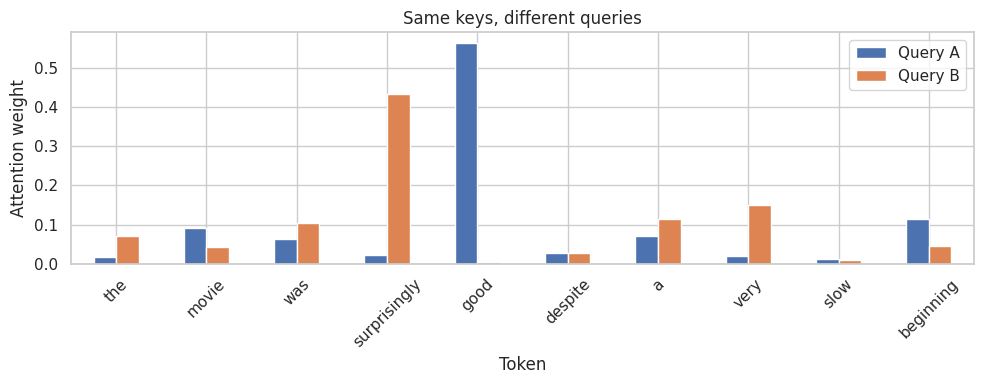

In [4]:
rng = np.random.default_rng(SEED + 3)
query_a, query_b = rng.normal(size=keys_exp1.shape[1]), rng.normal(size=keys_exp1.shape[1])
_, w_a, _ = dot_product_attention(query_a, keys_exp1, values_exp1)
_, w_b, _ = dot_product_attention(query_b, keys_exp1, values_exp1)
query_df = pd.DataFrame({'Token': tokens_exp1, 'Query A': w_a[0], 'Query B': w_b[0]})
display(query_df.round(4))
fig, ax = plt.subplots(figsize=(10, 4))
query_df.set_index('Token').plot.bar(ax=ax, rot=45)
ax.set(ylabel='Attention weight', title='Same keys, different queries')
save_figure(fig, 'query_comparison.png')

**Phân tích — Query thay đổi thì attention có thay đổi không?**

**Có.** Khi giữ nguyên keys/values và thay query, phân phối attention thay đổi rõ rệt. **Query A** tập trung mạnh nhất vào **`good` (0.5643)**, trong khi **Query B** tập trung vào **`surprisingly` (0.4334)**. Trọng số của `good` ở Query B chỉ còn **0.0039** so với **0.5643** ở Query A.

**Giải thích:** Mỗi query tạo ra một tập dot-product scores khác nhau với cùng các keys; softmax chuyển chúng thành các trọng số khác nhau. Vì thế attention phụ thuộc vào query, không phải một danh sách “từ quan trọng” cố định. Hai query này là **vector minh họa ngẫu nhiên**, chưa đại diện cho nhiệm vụ sentiment/topic đã học.

## 4. Experiment 3 — Attention visualization (mục 23)
Vẽ heatmap cho hai câu trong đề bằng self-attention NumPy. Embeddings/projections ngẫu nhiên, chưa train. Mỗi **hàng** là query, mỗi **cột** là key.

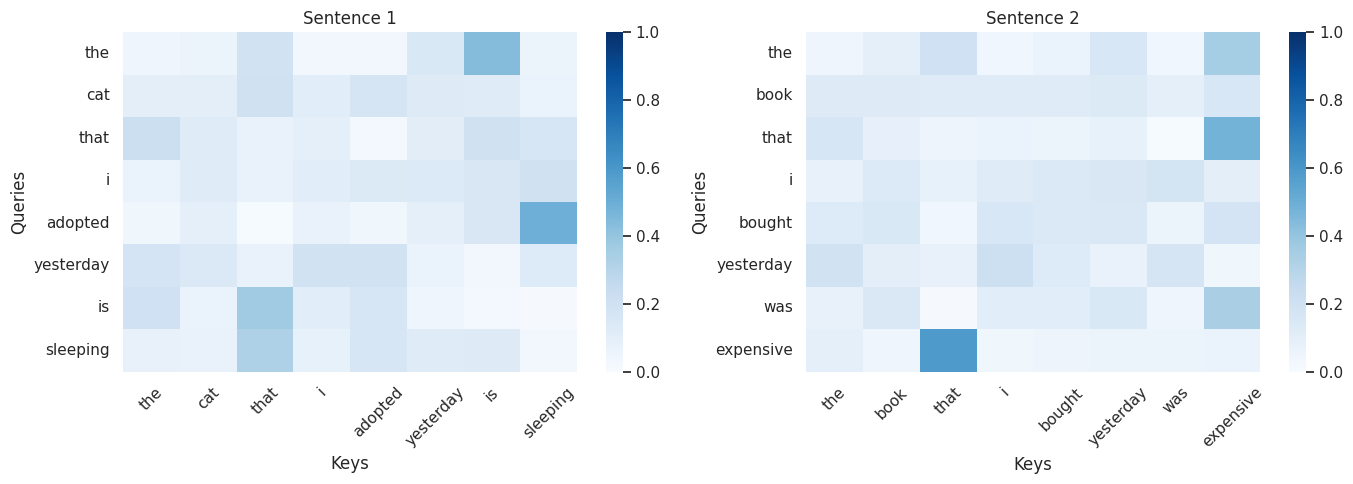

,Sentence,Query,Top key,Weight
0,1,cat,that,0.1963
1,1,adopted,sleeping,0.4955
2,1,sleeping,that,0.3261
3,2,book,expensive,0.1575
4,2,bought,expensive,0.1768
5,2,expensive,that,0.5871


In [5]:
sentences = [
    'The cat that I adopted yesterday is sleeping.',
    'The book that I bought yesterday was expensive.'
]
token_lists = [tokenizer(s) for s in sentences]
rng = np.random.default_rng(SEED + 4)
word_vectors = {w: rng.normal(size=6) for w in sorted(set(sum(token_lists, [])))}
WQ, WK, WV = [rng.normal(0, 1 / np.sqrt(6), size=(6, 4)) for _ in range(3)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_rows = []
for i, (tokens, ax) in enumerate(zip(token_lists, axes), 1):
    X = np.stack([word_vectors[t] for t in tokens])
    _, _, _, _, weights, _ = self_attention(X, WQ, WK, WV)
    assert np.allclose(weights.sum(axis=1), 1)
    sns.heatmap(weights, xticklabels=tokens, yticklabels=tokens, ax=ax, cmap='Blues', vmin=0, vmax=1)
    ax.set(title=f'Sentence {i}', xlabel='Keys', ylabel='Queries')
    ax.tick_params(axis='x', rotation=45)
    selected = ['cat', 'adopted', 'sleeping'] if i == 1 else ['book', 'bought', 'expensive']
    for token in selected:
        row = weights[tokens.index(token)]
        index = row.argmax()
        top_rows.append({'Sentence': i, 'Query': token, 'Top key': tokens[index], 'Weight': row[index]})
save_figure(fig, 'attention_heatmap.png')
display(pd.DataFrame(top_rows).round(4))

**Phân tích — Những token được chú ý đến trong heatmap?**

Từ bảng Top key ngay phía trên:

- **Câu 1:** Query `cat` chú ý nhiều nhất đến `that` (**0.1963**); `adopted` đến `sleeping` (**0.4955**); `sleeping` đến `that` (**0.3261**).
- **Câu 2:** Query `book` chú ý nhiều nhất đến `expensive` (**0.1575**); `bought` đến `expensive` (**0.1768**); `expensive` đến `that` (**0.5871**).

Mỗi **hàng** của attention matrix mô tả cách một query token phân bổ trọng số lên các key tokens. Các trọng số trên được tính từ embeddings/projections **ngẫu nhiên, chưa train**. Vì vậy heatmap chỉ cho thấy **attention pattern của phép tính này**, không chứng minh mô hình đã học quan hệ ngữ pháp hoặc hiểu nội dung câu.

## 5. Experiment 4 — LSTM vs Self-Attention (mục 24)

### 5.1. Đọc và xử lý IMDb theo W5

Sử dụng **đúng pipeline đọc dữ liệu ở `sequence_classification.ipynb` (LAB 05)**:

- File nén `aclImdb_v1.tar.gz` đã được upload vào `/content/` qua Files của Colab.
- Nếu 4 thư mục `train/neg`, `train/pos`, `test/neg`, `test/pos` chưa đủ 12.500 file mỗi thư mục, giải nén từ `/content/aclImdb_v1.tar.gz` vào `/content/w4` bằng `tarfile` như W5.
- Đọc review, tạo DataFrame và sử dụng cùng bước chia group-aware, vocabulary, DataLoader như W5.

Không dùng `files.upload()` hay `unpack_archive()`.

In [6]:
archive = Path("/content/aclImdb_v1.tar.gz")
root = Path("/content/w4/aclImdb")

def count_files():
    return [len(list((root / split / folder).glob("*.txt")))
            for split in ["train", "test"] for folder in ["neg", "pos"]]

if count_files() != [12500] * 4:
    if not archive.exists():
        raise FileNotFoundError(f"Không tìm thấy {archive}")
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall("/content/w4", filter="data")

counts = count_files()

def load_data(split):
    texts = []
    labels = []
    for label, folder in [(0, "neg"), (1, "pos")]:
        for file in sorted((root / split / folder).glob("*.txt")):
            texts.append(file.read_text(encoding="utf-8"))
            labels.append(label)
    return texts, labels

x_train_old, y_train_old = load_data("train")
x_test_old, y_test_old = load_data("test")

data = pd.DataFrame({
    "text": x_train_old + x_test_old,
    "label": y_train_old + y_test_old
})

display(data.head())
display(pd.DataFrame({
    "Tập gốc": ["train/neg", "train/pos", "test/neg", "test/pos"],
    "Số review": counts
}))

assert len(data) == 50000, f'IMDb cần 50.000 reviews, hiện có {len(data)}.'
data['group'] = data['text'].map(lambda s: hashlib.md5(clean_text(s).encode('utf-8')).hexdigest())


,text,label
0,Story of a man who has unnatural feelings for ...,0
1,Airport '77 starts as a brand new luxury 747 p...,0
2,This film lacked something I couldn't put my f...,0
3,"Sorry everyone,,, I know this is supposed to b...",0
4,When I was little my parents took me along to ...,0


,Tập gốc,Số review
0,train/neg,12500
1,train/pos,12500
2,test/neg,12500
3,test/pos,12500


In [7]:
group_labels = data.groupby('group')['label'].first()
train_groups, other_groups = train_test_split(group_labels.index.to_numpy(), test_size=0.3,
    random_state=SEED, stratify=group_labels.to_numpy())
val_groups, test_groups = train_test_split(other_groups, test_size=0.5,
    random_state=SEED, stratify=group_labels.loc[other_groups].to_numpy())
train = data[data.group.isin(train_groups)].reset_index(drop=True)
val = data[data.group.isin(val_groups)].reset_index(drop=True)
test = data[data.group.isin(test_groups)].reset_index(drop=True)
display(pd.DataFrame({'Split': ['Train', 'Validation', 'Test'],
    'Reviews': [len(train), len(val), len(test)]}))

counter = Counter()
for text in train.text:
    counter.update(tokenizer(text))
vocab = {'<PAD>': PAD, '<UNK>': UNK}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode(text):
    ids = [vocab.get(t, UNK) for t in tokenizer(text)][:MAX_LEN] or [UNK]
    return ids + [PAD] * (MAX_LEN - len(ids)), len(ids)

class ReviewDataset(Dataset):
    def __init__(self, frame):
        samples = [encode(text) for text in frame.text]
        self.ids = torch.tensor([sample[0] for sample in samples], dtype=torch.long)
        self.lengths = torch.tensor([sample[1] for sample in samples], dtype=torch.long)
        self.labels = torch.tensor(frame.label.to_numpy(), dtype=torch.float32)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return self.ids[index], self.lengths[index], self.labels[index]

datasets = [ReviewDataset(frame) for frame in (train, val, test)]
def make_loaders():
    g = torch.Generator().manual_seed(SEED)
    return (DataLoader(datasets[0], batch_size=BATCH_SIZE, shuffle=True, generator=g),
            DataLoader(datasets[1], batch_size=BATCH_SIZE),
            DataLoader(datasets[2], batch_size=BATCH_SIZE))
print('Vocabulary:', len(vocab), '| Max length:', MAX_LEN)

,Split,Reviews
0,Train,34999
1,Validation,7499
2,Test,7502


Vocabulary: 20000 | Max length: 200


### 5.2. Hai mô hình
LSTM: Embedding → LSTM → final hidden state → Linear. Attention: Embedding → Q/K/V → scaled self-attention → masked mean pooling → Linear. Attention model này **không có positional encoding**.

In [8]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBED_DIM, padding_idx=PAD)
        self.lstm = nn.LSTM(EMBED_DIM, HIDDEN_SIZE, batch_first=True)
        self.fc = nn.Linear(HIDDEN_SIZE, 1)
    def forward(self, ids, lengths):
        x = self.embedding(ids)
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        return self.fc(hidden[-1]).squeeze(-1)

class AttentionClassifier(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBED_DIM, padding_idx=PAD)
        self.WQ = nn.Linear(EMBED_DIM, HIDDEN_SIZE, bias=False)
        self.WK = nn.Linear(EMBED_DIM, HIDDEN_SIZE, bias=False)
        self.WV = nn.Linear(EMBED_DIM, HIDDEN_SIZE, bias=False)
        self.fc = nn.Linear(HIDDEN_SIZE, 1)
    def forward(self, ids, lengths, return_attention=False):
        valid = ids != PAD
        X = self.embedding(ids)
        Q, K, V = self.WQ(X), self.WK(X), self.WV(X)
        scores = Q @ K.transpose(-2, -1) / math.sqrt(HIDDEN_SIZE)
        scores = scores.masked_fill(~valid[:, None, :], -1e9)  # loại PAD keys
        weights = torch.softmax(scores, dim=-1) * valid[:, :, None]
        context = weights @ V
        pooled = context.sum(1) / valid.sum(1, keepdim=True).clamp_min(1)
        logits = self.fc(pooled).squeeze(-1)
        return (logits, weights) if return_attention else logits

### 5.3. Training và evaluation
Cùng tokenization, dataset, optimizer, learning rate, epoch. Chọn checkpoint theo **validation F1**, sau đó đánh giá test.

In [9]:
def evaluate(model, loader):
    model.eval()
    true, probs, losses = [], [], []
    with torch.no_grad():
        for ids, lengths, labels in loader:
            logits = model(ids.to(device), lengths)
            p = torch.sigmoid(logits).cpu().numpy()
            true.extend(labels.numpy().astype(int))
            probs.extend(p)
            losses.append((nn.functional.binary_cross_entropy_with_logits(
                logits, labels.to(device), reduction='sum')).item())
    true, probs = np.asarray(true), np.asarray(probs)
    return {'true': true, 'prob': probs, 'pred': (probs >= .5).astype(int),
            'loss': sum(losses) / len(true)}

def scores_from_result(result):
    precision, recall, f1, _ = precision_recall_fscore_support(
        result['true'], result['pred'], average='binary', zero_division=0)
    return dict(Accuracy=accuracy_score(result['true'], result['pred']), F1=f1,
                Precision=precision, Recall=recall)

def train_model(model, train_loader, val_loader):
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.BCEWithLogitsLoss()
    history, best_f1, best_state = [], -1, None
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0
        for ids, lengths, labels in train_loader:
            ids, labels = ids.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(ids, lengths), labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * len(labels)
        val_result = evaluate(model, val_loader)
        val_f1 = scores_from_result(val_result)['F1']
        history.append({'Epoch': epoch, 'Train loss': total_loss / len(train_loader.dataset),
                        'Validation loss': val_result['loss'], 'Validation F1': val_f1})
        print(f'Epoch {epoch}: train loss={history[-1]["Train loss"]:.4f}, val F1={val_f1:.4f}')
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if device.type == 'cuda':
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    return pd.DataFrame(history), seconds

models, histories, test_outputs, rows = {}, {}, {}, []
for name, Model in [('LSTM', LSTMClassifier), ('Attention', AttentionClassifier)]:
    set_seed()
    train_loader, val_loader, test_loader = make_loaders()
    model = Model(len(vocab)).to(device)
    history, seconds = train_model(model, train_loader, val_loader)
    result = evaluate(model, test_loader)
    models[name], histories[name], test_outputs[name] = model, history, result
    rows.append({'Model': name, **scores_from_result(result), 'Training time (s)': seconds,
                 'Parameters': sum(p.numel() for p in model.parameters() if p.requires_grad)})
results_df = pd.DataFrame(rows)

Epoch 1: train loss=0.6471, val F1=0.7398
Epoch 2: train loss=0.5076, val F1=0.7996
Epoch 3: train loss=0.4049, val F1=0.8303
Epoch 1: train loss=0.5415, val F1=0.8048
Epoch 2: train loss=0.3670, val F1=0.8443
Epoch 3: train loss=0.2980, val F1=0.8604


,Model,Accuracy,F1,Training time (s),Parameters
0,LSTM,0.8244,0.8290,13.4611,1313345
1,Attention,0.8526,0.8525,6.0718,1292353


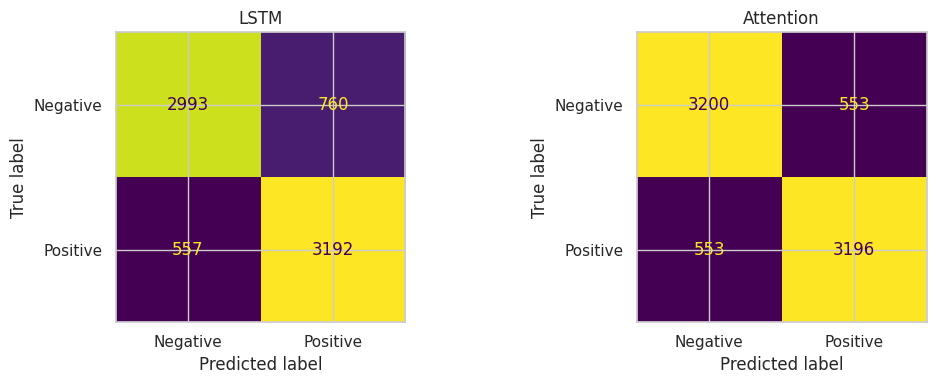

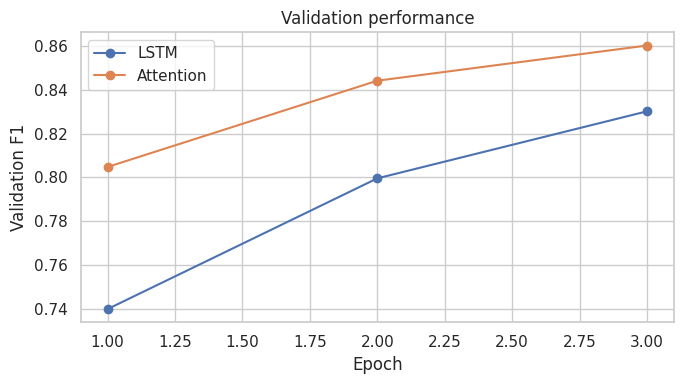

In [10]:
display(results_df[['Model', 'Accuracy', 'F1', 'Training time (s)', 'Parameters']].round(4))
results_df.to_csv(OUTPUT_DIR / 'results.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ['LSTM', 'Attention']):
    result = test_outputs[name]
    ConfusionMatrixDisplay.from_predictions(result['true'], result['pred'],
        labels=[0, 1], display_labels=['Negative', 'Positive'], ax=ax, colorbar=False)
    ax.set_title(name)
save_figure(fig, 'confusion_matrix.png')
fig, ax = plt.subplots(figsize=(7, 4))
for name, hist in histories.items():
    ax.plot(hist.Epoch, hist['Validation F1'], 'o-', label=name)
ax.set(xlabel='Epoch', ylabel='Validation F1', title='Validation performance')
ax.legend()
save_figure(fig, 'learning_curves.png')

**Phân tích — Representation của LSTM và Self-Attention khác nhau ở đâu?**

**LSTM** xử lý token theo thứ tự qua các bước recurrent và dùng **final hidden state** làm vector biểu diễn cả câu. Thông tin từ các token đầu phải được truyền qua nhiều bước để ảnh hưởng tới kết quả cuối. **Self-Attention** tạo $Q,K,V$ từ embeddings, dùng attention weights để tổng hợp thông tin từ các token thành contextual representations; sau đó dùng **masked mean pooling** tạo vector đưa vào classifier. Cách này cho phép tương tác trực tiếp giữa các vị trí và thuận lợi hơn cho tính toán song song. Tuy nhiên, kiến trúc single-head attention ở notebook **không có positional encoding**, nên không mã hóa tường minh thứ tự token như LSTM.

**Kết quả test của lần chạy đang được lưu trong notebook:**

| Model | Accuracy | F1 | Training time | Parameters |
|---|---:|---:|---:|---:|
| LSTM | **82.44%** | **0.8290** | **13.4611 s** | **1,313,345** |
| Attention | **85.26%** | **0.8525** | **6.0718 s** | **1,292,353** |

Attention cao hơn **2.82 điểm phần trăm Accuracy** và **0.0235 F1** trong lần chạy này, đồng thời có ít hơn **20,992 tham số**. Ở validation, F1 epoch 3 tương ứng là **0.8303** (LSTM) và **0.8604** (Attention). Số liệu training time đo trên lần chạy này, có thể khác trên phần cứng hoặc phiên chạy khác. **Không thể kết luận Attention luôn tốt hơn LSTM** chỉ từ một lần huấn luyện 3 epochs.

## 6. Experiment 5 — Sequence length & cost (mục 25)
Ma trận attention có $T^2$ phần tử. Ước lượng dưới đây chỉ tính **một ma trận float32**; không bao gồm gradients hoặc các tensor khác.

,Sequence length,Attention matrix,Elements,Float32 memory (MB)
0,10,10 × 10,100,0.0004
1,100,100 × 100,10000,0.0400
2,500,500 × 500,250000,1.0000
3,1000,1000 × 1000,1000000,4.0000


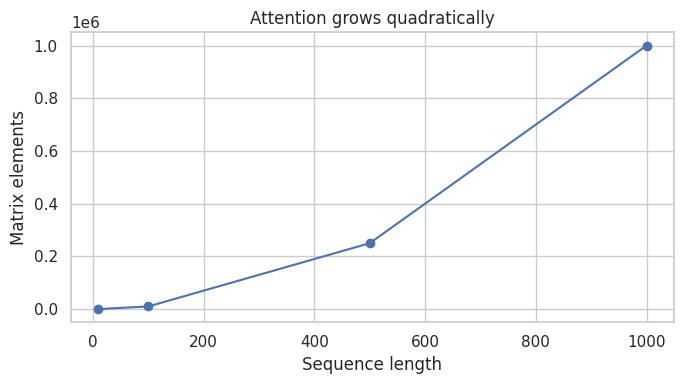

In [11]:
lengths = [10, 100, 500, 1000]
cost_df = pd.DataFrame({'Sequence length': lengths,
    'Attention matrix': [f'{t} × {t}' for t in lengths],
    'Elements': [t * t for t in lengths],
    'Float32 memory (MB)': [t * t * 4 / 1e6 for t in lengths]})
display(cost_df)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lengths, cost_df['Elements'], 'o-')
ax.set(xlabel='Sequence length', ylabel='Matrix elements', title='Attention grows quadratically')
save_figure(fig, 'sequence_length_cost.png')

**Phân tích — Vì sao sequence dài gây tốn chi phí?**

Full self-attention tính tương tác của mỗi token với tất cả token khác nên một attention matrix có kích thước $T\times T$, tương ứng **$T^2$ phần tử**. Bảng cho thấy: $T=10$ có **100** phần tử (**0.0004 MB**), $T=100$ có **10,000** (**0.04 MB**), $T=500$ có **250,000** (**1 MB**), và $T=1,000$ có **1,000,000** (**4 MB**) nếu mỗi phần tử float32 chiếm 4 byte.

Khi độ dài tăng **10 lần**, số phần tử tăng **100 lần**. Đây chỉ là dung lượng của **một ma trận attention**, chưa tính batch, gradients và các tensors trung gian; vì vậy chi phí bộ nhớ/tính toán trở thành hạn chế đáng kể với sequence dài.

## 7. Application — Context-aware sentiment (mục 26)
Dùng lại Attention model từ Experiment 4; lấy prediction và attention của ba câu đề bài.

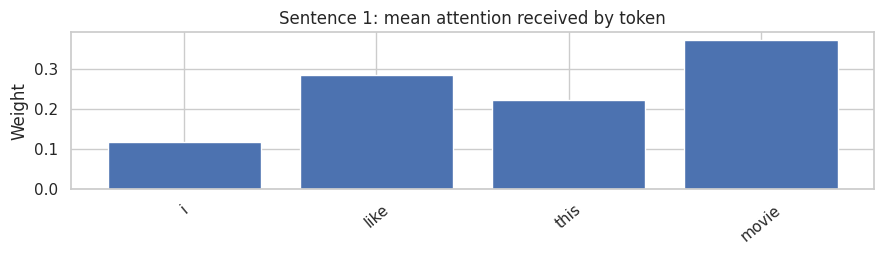

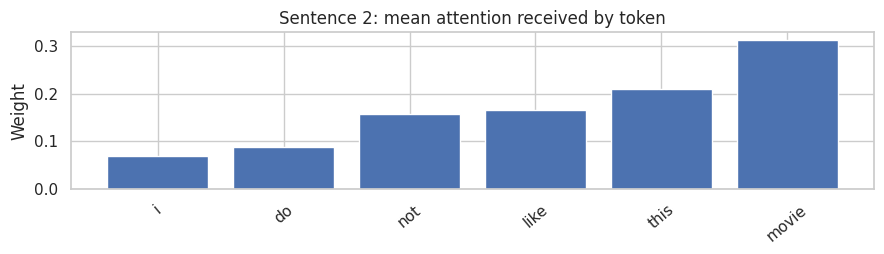

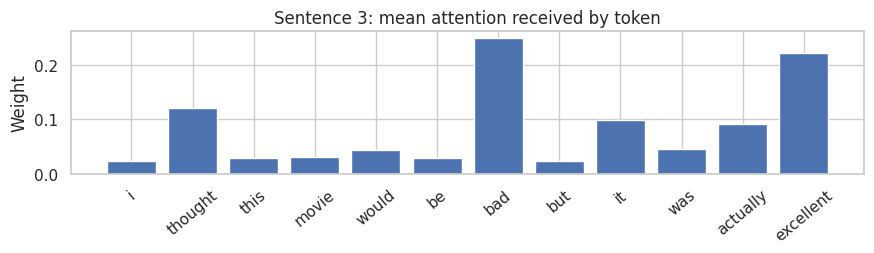

,Sentence,Prediction,P(positive)
0,I like this movie.,Negative,0.00001
1,I do not like this movie.,Negative,0.00002
2,"I thought this movie would be bad, but it was ...",Negative,0.01498


In [12]:
def predict_attention(text):
    ids, length = encode(text)
    model = models['Attention'].eval()
    with torch.no_grad():
        logit, weights = model(torch.tensor([ids], device=device),
                               torch.tensor([length]), return_attention=True)
    p = torch.sigmoid(logit).item()
    tokens = tokenizer(text)[:MAX_LEN] or ['<UNK>']
    matrix = weights[0, :length, :length].cpu().numpy()
    return {'tokens': tokens, 'prob': p, 'prediction': int(p >= .5),
            'weights': matrix, 'mean_received': matrix.mean(axis=0)}

examples = [
    'I like this movie.',
    'I do not like this movie.',
    'I thought this movie would be bad, but it was actually excellent.'
]
application_rows = []
for i, sentence in enumerate(examples, 1):
    result = predict_attention(sentence)
    application_rows.append({'Sentence': sentence,
        'Prediction': 'Positive' if result['prediction'] else 'Negative',
        'P(positive)': result['prob']})
    fig, ax = plt.subplots(figsize=(9, 2.7))
    ax.bar(result['tokens'], result['mean_received'])
    ax.set(title=f'Sentence {i}: mean attention received by token', ylabel='Weight')
    ax.tick_params(axis='x', rotation=40)
    save_figure(fig, f'application_attention_{i}.png')
display(pd.DataFrame(application_rows).round(5))

**Phân tích — Model phản ứng thế nào với phủ định và câu chuyển ý?**

Trong bảng dự đoán của lần chạy đã lưu, mô hình Attention dự đoán cả ba câu là **Negative**:

- `I like this movie.` → **Negative**, $P(positive)\approx 0.00001$.
- `I do not like this movie.` → **Negative**, $P(positive)\approx 0.00002$.
- `I thought this movie would be bad, but it was actually excellent.` → **Negative**, $P(positive)\approx 0.01498$.

Dự đoán ở câu **có phủ định** phù hợp với sắc thái tiêu cực. Ngược lại, câu **“I like this movie”** và câu **chuyển ý với “but ... excellent”** thường được hiểu theo hướng tích cực nhưng vẫn bị dự đoán Negative. Điều này cho thấy model có thể thất bại với những cách diễn đạt cụ thể, dù kết quả F1 trên tập IMDb là **0.8525**. Các câu trên là ví dụ kiểm tra định tính, **không phải thước đo accuracy riêng**; biểu đồ attention cũng không đủ chứng minh nguyên nhân dự đoán sai.

## 8. Error Analysis (mục 27)
Chọn **3 dự đoán đúng và 3 dự đoán sai** trên test set; đánh dấu các dấu hiệu cần xem xét. Phân tích chi tiết cuối cùng thuộc `error_analysis.md`.

,Index,Review,True,Predicted,P(positive),Result,Possible signals
0,1,This film is mediocre at best. Angie Harmon is...,0,0,4.148207e-02,Correct,read context manually
1,2,The characters are unlikeable and the script i...,0,0,5.458883e-08,Correct,read context manually
2,3,The action in this movie beats Sunny bhai in G...,0,0,1.230389e-01,Correct,"negation, UNK tokens"
3,0,"Sorry everyone,,, I know this is supposed to b...",0,1,5.121635e-01,Incorrect,"negation, contrast, UNK tokens"
4,10,I figured that it's about time I let this one ...,0,1,9.744425e-01,Incorrect,"negation, contrast, truncated 838 tokens, UNK ..."
5,12,"When I was 11, Grease 2 was like crack. It was...",0,1,7.313054e-01,Incorrect,"negation, contrast, truncated 344 tokens, UNK ..."


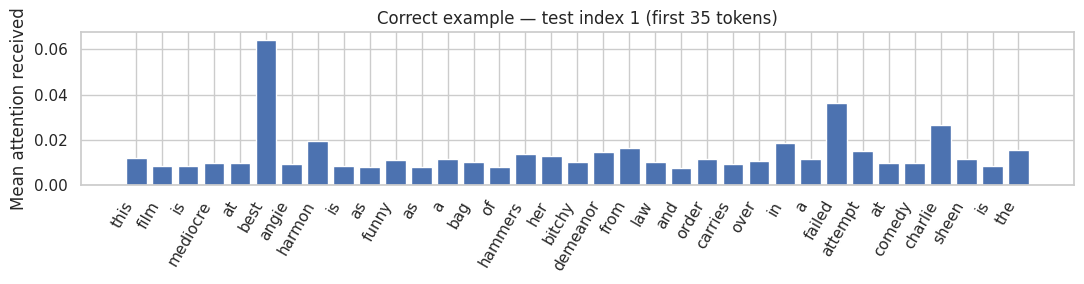

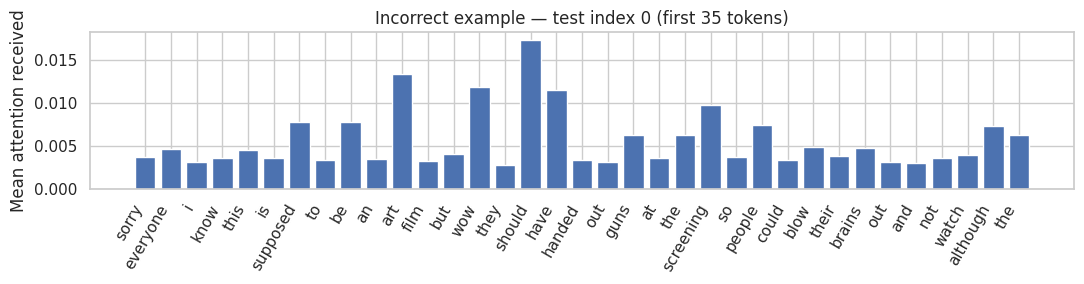

In [13]:
def possible_signals(text):
    tokens = tokenizer(text)
    flags = []
    if any(t in tokens for t in ['not', 'no', 'never', 'neither']):
        flags.append('negation')
    if any(t in tokens for t in ['but', 'however', 'although', 'though', 'yet']):
        flags.append('contrast')
    if len(tokens) > MAX_LEN:
        flags.append(f'truncated {len(tokens) - MAX_LEN} tokens')
    if sum(t not in vocab for t in tokens[:MAX_LEN]):
        flags.append('UNK tokens')
    return ', '.join(flags) or 'read context manually'

result = test_outputs['Attention']
correct = np.where(result['true'] == result['pred'])[0][:3]
incorrect = np.where(result['true'] != result['pred'])[0][:3]
indices = list(correct) + list(incorrect)
error_df = pd.DataFrame([{'Index': int(i), 'Review': test.iloc[i]['text'][:220],
    'True': int(result['true'][i]), 'Predicted': int(result['pred'][i]),
    'P(positive)': float(result['prob'][i]),
    'Result': 'Correct' if i in correct else 'Incorrect',
    'Possible signals': possible_signals(test.iloc[i]['text'])} for i in indices])
display(error_df)
error_df.to_csv(OUTPUT_DIR / 'error_analysis.csv', index=False)

# Minh họa attention cho một ví dụ đúng và một ví dụ sai.
for title, i in [('Correct', correct[0]), ('Incorrect', incorrect[0])]:
    prediction = predict_attention(test.iloc[i]['text'])
    n = min(len(prediction['tokens']), 35)
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.bar(range(n), prediction['mean_received'][:n])
    ax.set_xticks(range(n), prediction['tokens'][:n], rotation=60, ha='right')
    ax.set(ylabel='Mean attention received', title=f'{title} example — test index {i} (first {n} tokens)')
    save_figure(fig, f'error_{title.lower()}.png')

**Phân tích — Có thể giải thích lỗi bằng attention không?**

Bảng Error Analysis đang chọn **3 mẫu đúng và 3 mẫu sai** trên test set của mô hình Attention:

- **Dự đoán đúng:** test indices **1, 2, 3** đều là **Negative → Negative**, với $P(positive)$ lần lượt khoảng **0.04148**, **0.000000055** và **0.12304**.
- **Dự đoán sai:** test indices **0, 10, 12** đều là **Negative → Positive**, với $P(positive)$ lần lượt khoảng **0.51216**, **0.97444** và **0.73131**.

Mẫu **index 0** ở sát ngưỡng phân loại **0.5**, nên dự đoán không chắc chắn như hai mẫu sai còn lại. Mẫu **index 10** bị cắt **838 token** và mẫu **index 12** bị cắt **344 token** khi giới hạn `MAX_LEN=200`: việc mất phần cuối review **có thể** ảnh hưởng tới dự đoán. Ngoài ra, hàm dò dấu hiệu còn đánh dấu negation, contrast và UNK tokens ở một số review. Đây là **những giả thuyết cần kiểm chứng**, không phải nguyên nhân đã được chứng minh.

**Attention có nhìn vào token quan trọng không?** Hai biểu đồ hiển thị *mean attention received* cho một mẫu đúng và một mẫu sai, nhưng không có nhãn chuẩn xác định token nào “quan trọng” để đối chiếu. Trọng số attention cao cũng không đồng nghĩa token đó gây ra dự đoán. Vì vậy, **không thể kết luận “model sai vì attention nhìn sai từ”** chỉ dựa vào heatmap. Có thể kiểm tra thêm bằng thử nghiệm thay đổi `MAX_LEN` hoặc loại/thay từ khóa rồi đo lại xác suất.

## 9. Comparison — LAB 05 vs LAB 06 (mục 28)

| Tiêu chí | LSTM | Self-Attention trong notebook |
|---|---|---|
| Representation | Final recurrent hidden state | Contextual token vectors kết hợp bằng masked pooling |
| Thứ tự token | Được thể hiện qua chuỗi cập nhật recurrent | Không có positional encoding nên không mã hóa thứ tự tường minh |
| Tương tác xa | Thông tin đi qua nhiều bước hidden state | Token tương tác trực tiếp qua attention weights |
| Tính song song theo vị trí | Hạn chế bởi sự phụ thuộc theo timestep | Thuận lợi hơn trong phép tính ma trận |
| Chi phí theo độ dài | Lặp qua $T$ bước | Attention matrix có $T^2$ phần tử |

**Trả lời câu hỏi:** Attention giúp các vị trí trong sequence kết hợp thông tin trực tiếp thay vì phải đi tuần tự qua hidden state, nhưng tạo ra chi phí ma trận bậc hai theo độ dài chuỗi. Riêng self-attention cơ bản trong notebook còn thiếu biểu diễn vị trí. Trong **kết quả test đã lưu**, Attention đạt **85.26% Accuracy**, cao hơn LSTM **82.44%**; đây chỉ là kết quả của hai model và thiết lập thí nghiệm hiện tại, **không phải bằng chứng Attention luôn thắng LSTM**.

## 10. Attention không miễn phí (mục 29)
Tính riêng hai trường hợp đề bài yêu cầu mà **không cấp phát ma trận rất lớn**.

In [14]:
large_df = pd.DataFrame({
    'Sequence length': [1000, 10000],
    'Matrix elements': [1000**2, 10000**2],
    'Memory for one float32 matrix (MB)': [1000**2 * 4 / 1e6, 10000**2 * 4 / 1e6]
})
display(large_df)

,Sequence length,Matrix elements,Memory for one float32 matrix (MB)
0,1000,1000000,4.0
1,10000,100000000,400.0


**Phân tích — Attention không miễn phí (mục 29)**

Khi độ dài sequence tăng từ **$T=1,000$** lên **$T=10,000$**, ma trận full self-attention tăng từ **1,000,000** lên **100,000,000 phần tử** — tức tăng **100 lần** dù $T$ chỉ tăng 10 lần. Với float32 (4 byte/phần tử), dung lượng một ma trận tương ứng khoảng **4 MB** và **400 MB**. Con số này **chưa tính** batch, gradients, các ma trận trung gian và các lớp khác. Vì vậy full self-attention gặp trở ngại lớn về bộ nhớ khi xử lý sequence rất dài.

**AI assistance statement:** AI hỗ trợ chỉnh sửa phần nhận xét/Analytics cho khớp các số liệu đã lưu trong notebook. Người nộp cần tự đối chiếu, giải thích và xác nhận phần diễn giải theo AI Policy mục 30 của W6.